In [24]:
%%writefile kernel.cu

#include <cuda_runtime.h>
#include <curand_kernel.h>
#include <iostream>
#include <math_constants.h>
#include <cmath>


__global__ void esitmatePi(
  unsigned long long *d_inside_count,
  unsigned long long trials_per_thread,
  unsigned long long seed
  )
  {
    int tid = blockIdx.x * blockDim.x + threadIdx.x;

    curandState state;
    curand_init(seed, tid, 0, &state);

    unsigned long long local_inside = 0;

    for (unsigned long long i = 0; i < trials_per_thread; ++i) {
      float x = curand_uniform(&state);
      float y = curand_uniform(&state);

      if ((x * x + y * y) <= 1.0f) {
        local_inside++;
      }
    }
    atomicAdd(d_inside_count, local_inside);
  }

int main() {
  int threads_per_block = 256;
  int blocks_per_grid = 4096;
  unsigned long long trials_per_thread = 10000;

  unsigned long long total_threads = threads_per_block * blocks_per_grid;
  unsigned long long total_trials = total_threads * trials_per_thread;

  std::cout << "Launching " << total_threads << " concurrent threads..." << std::endl;
  std::cout << "Running a total of " << total_trials << " Monte Carlo trials." << std::endl;

  unsigned long long *d_inside_count;
  cudaMalloc((void**)&d_inside_count, sizeof(unsigned long long));
  cudaMemset(d_inside_count, 0, sizeof(unsigned long long));

  unsigned long long seed = 1234ULL;

  esitmatePi<<<blocks_per_grid, threads_per_block>>>(d_inside_count, trials_per_thread, seed);

  cudaDeviceSynchronize();

  unsigned long long h_inside_count = 0;
  cudaMemcpy(&h_inside_count, d_inside_count, sizeof(unsigned long long), cudaMemcpyDeviceToHost);

  double estimate = 4.0 * (double)h_inside_count / (double)total_trials;

  double compare = M_PIf64;

  double diff = std::max(compare, estimate) - std::min(compare, estimate);
  double error = (diff / compare) * 100.0;

  std::cout << "Points inside circle: " << h_inside_count << "\n";
  std::cout << "Estimated PI Value: " << estimate << "\n";
  std::cout << "Error: " << error << "%\n";

  cudaFree(d_inside_count);
  return 0;
}

Overwriting kernel.cu


In [25]:
!nvcc kernel.cu -o kernel -lcurand
!./kernel

Launching 1048576 concurrent threads...
Running a total of 10485760000 Monte Carlo trials.
Points inside circle: 8235506170
Estimated PI Value: 3.1416
Error: 0.000115648%


In [18]:
import triton
import math
import torch
import triton.language as tl

@triton.jit
def estimate_pi_kernel(
    inside_count,
    trials_per_block,
    BLOCK_SIZE: tl.constexpr
):

    block_id = tl.program_id(0)
    block_inside_accum = tl.zeros((BLOCK_SIZE,), dtype=tl.int64)

    num_loops = trials_per_block // BLOCK_SIZE

    for i in range(num_loops):
      offsets = tl.arange(0, BLOCK_SIZE)

      seed_x = block_id * trials_per_block + i * BLOCK_SIZE + offsets
      seed_y = seed_x + 987654321

      x = tl.rand(seed_x, offsets)
      y = tl.rand(seed_y, offsets)


      is_inside = (x * x) + (y * y) < 1.0

      block_inside_accum += tl.where(is_inside, 1, 0)

    total_hits = tl.sum(block_inside_accum, axis=0)

    tl.atomic_add(inside_count, total_hits)

def run_simulation(trials_per_block):
    grid_size = 4096
    block_size = 512

    total_trials = grid_size * trials_per_block

    inside_count = torch.zeros(1, dtype=torch.int64, device="cuda")

    estimate_pi_kernel[(grid_size,)](
        inside_count,
        trials_per_block=trials_per_block,
        BLOCK_SIZE=block_size
    )

    torch.cuda.synchronize()

    total_hits = inside_count.item()
    pi_estimate = 4.0 * total_hits / total_trials

    diff = abs(pi_estimate - math.pi)
    error = (diff / math.pi) * 100

    return pi_estimate, error


<Axes: >

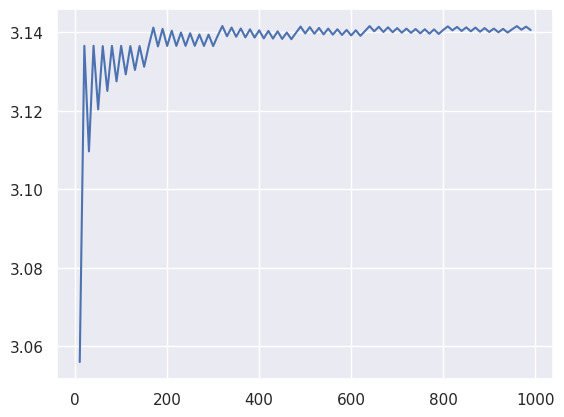

In [20]:
import seaborn as sns

sns.set_theme(style="darkgrid")

approximates = []
x = []
for i in range(10, 1000, 10):
  estimate, error = run_simulation(i * 1000)
  approximates.append(estimate)
  x.append(i)

sns.lineplot(x=x, y=approximates)